In [1]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import StratifiedShuffleSplit, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from imblearn.over_sampling import SMOTE

# Load your dataset
df = pd.read_csv('2yr_cleaned.txt', delimiter=',')

# Find the ids in df1 that are not in df2
ids_to_keep = set(df['ID_PIEZO']) - set([1740])

# Select the rows with these ids
df = df[df['ID_PIEZO'].isin(ids_to_keep)]




In [2]:
# Get unique values in the 'ID_PIEZO' column
unique_piezo_values = df['ID_PIEZO'].unique()


# Choose specific values from the list of unique 'ID_PIEZO' values
selected_piezo_values = [1267,2663, 2664, 2665, 2666]  # Replace with the specific values you want to choose

# Update the 'REP' labels for the selected 'ID_PIEZO' values
df.loc[df['ID_PIEZO'].isin(selected_piezo_values), 'REPORTABLE'] = True

In [3]:
# Assuming your DataFrame is named 'df'
unique_piezo_ids = df['ID_PIEZO'].unique()

for piezo_id in unique_piezo_ids:
    piezo_subset = df[df['ID_PIEZO'] == piezo_id]
    
    max_digits = piezo_subset['DIGITS'].max()
    min_digits = piezo_subset['DIGITS'].min()
    if max_digits < 10000 and min_digits > 4500:
        df.loc[df['ID_PIEZO'] == piezo_id, 'AMP'] = 3.5                 #np.random.uniform(2.5, 3.5)
    elif max_digits <= 4500:
        df.loc[df['ID_PIEZO'] == piezo_id, 'AMP'] = 0                    #np.random.uniform(0, 1)
    elif  max_digits > -1000 and min_digits < 4500:
        df.loc[(df['ID_PIEZO'] == piezo_id) & (df['DIGITS'] >= 8000), 'AMP'] = 3.5      #np.random.uniform(2.5, 3.5)
    elif max_digits > -1000 and min_digits < 4500:       
        df.loc[(df['ID_PIEZO'] == piezo_id) & (df['DIGITS'] < 8000), 'AMP'] = 0          #np.random.uniform(0, 1)
        

In [4]:
df['TM_STAMP'] = (pd.to_datetime(df['TM_STAMP']).astype('int64') // 10**9)

In [5]:
df

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,ID_PIEZO,TM_STAMP,DIGITS,AMP,SIG2NOISE,REPORTABLE
0,0,0,0,0,392,1609459200,8679.682617,3.5,580.325806,True
1,1,1,1,1,392,1609462800,8679.713867,3.5,536.404236,True
2,2,2,2,2,392,1609466400,8679.676758,3.5,758.372925,True
3,3,3,3,3,392,1609470000,8679.657227,3.5,615.265381,True
4,4,4,4,4,392,1609473600,8679.676758,3.5,718.530701,True
...,...,...,...,...,...,...,...,...,...,...
20701484,20701484,22345305,22345305,22345305,2561,1640998800,8743.775391,3.5,4637.093750,True
20701485,20701485,22345306,22345306,22345306,2560,1640995200,8916.651367,3.5,1025.008545,True
20701486,20701486,22345307,22345307,22345307,2560,1640998800,8916.620117,3.5,861.051147,True
20701487,20701487,22345308,22345308,22345308,2559,1640995200,8985.988281,3.5,1071.302979,True


In [6]:
data = df[['ID_PIEZO','TM_STAMP','DIGITS','AMP','REPORTABLE']]

In [7]:
# Split the dataset into input features and target variable
X = data.drop('REPORTABLE', axis=1)
y = data['REPORTABLE']

In [8]:
# Stratify the data based on the 'ID_PIEZO' column
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
for train_index, test_index in sss.split(X, data['ID_PIEZO']):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

# Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Apply SMOTE to balance the dataset
#smote = SMOTE(random_state=42)
#X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Initialize the XGBoost classifier
classifier = xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')

# Set up a parameter grid for hyperparameter tuning using cross-validation
param_grid = {
    'learning_rate': [0.01, 0.1],
    'max_depth': [3, 5],
    'n_estimators': [100, 200],
    'subsample': [0.8, 1],
    'colsample_bytree': [0.8, 1],
}

# Apply RandomizedSearchCV for faster hyperparameter tuning
random_search = RandomizedSearchCV(classifier, param_grid, scoring='f1', cv=3, n_iter=10, n_jobs=-1)
random_search.fit(X_train, y_train)

# Train the classifier with the best hyperparameters
best_classifier = random_search.best_estimator_
best_classifier.fit(X_train, y_train)

# Evaluate the classifier
y_pred = best_classifier.predict(X_test)
print(classification_report(y_test, y_pred))


C:\Users\Michael.Tetteh\AppData\Local\anaconda3\lib\site-packages\xgboost\sklearn.py:1395: UserWarning: `use_label_encoder` is deprecated in 1.7.0.
  warnings.warn("`use_label_encoder` is deprecated in 1.7.0.")
C:\Users\Michael.Tetteh\AppData\Local\anaconda3\lib\site-packages\xgboost\sklearn.py:1395: UserWarning: `use_label_encoder` is deprecated in 1.7.0.
  warnings.warn("`use_label_encoder` is deprecated in 1.7.0.")
C:\Users\Michael.Tetteh\AppData\Local\anaconda3\lib\site-packages\xgboost\sklearn.py:1395: UserWarning: `use_label_encoder` is deprecated in 1.7.0.
  warnings.warn("`use_label_encoder` is deprecated in 1.7.0.")


              precision    recall  f1-score   support

       False       1.00      1.00      1.00    101974
        True       1.00      1.00      1.00   6103328

    accuracy                           1.00   6205302
   macro avg       1.00      1.00      1.00   6205302
weighted avg       1.00      1.00      1.00   6205302



In [9]:
val = pd.read_csv('Q3_2019.txt', delimiter=',')
# Find the ids in df1 that are not in df2
ids_to_keep = set(val['ID_PIEZO']) - set([1740])

# Select the rows with these ids
val = val[val['ID_PIEZO'].isin(ids_to_keep)]
val = val.dropna()

In [10]:
# Assuming your DataFrame is named 'df'
unique_piezo_ids1 = val['ID_PIEZO'].unique()

for piezo_id in unique_piezo_ids1:
    piezo_subset = val[val['ID_PIEZO'] == piezo_id]
    
    max_digits = piezo_subset['DIGITS'].max()
    min_digits = piezo_subset['DIGITS'].min()
    
    if max_digits < 10000 and min_digits > 4500:
        val.loc[val['ID_PIEZO'] == piezo_id, 'AMP'] = 3.5               #np.random.uniform(2.5, 3.5)
    elif max_digits <= 4500:
        val.loc[val['ID_PIEZO'] == piezo_id, 'AMP'] = 0                  #np.random.uniform(0, 1)
    elif  max_digits > -1000 and min_digits < 4500:
        val.loc[(val['ID_PIEZO'] == piezo_id) & (val['DIGITS'] >= 8000), 'AMP'] = 3.5             #np.random.uniform(2.5, 3.5)
    elif max_digits > -1000 and min_digits < 4500:       
        val.loc[(val['ID_PIEZO'] == piezo_id) & (val['DIGITS'] < 8000), 'AMP'] = 0                 #np.random.uniform(0, 1)

In [11]:
val['TM_STAMP'] = (pd.to_datetime(val['TM_STAMP']).astype('int64') // 10**9)

In [12]:
val1 = val[['ID_PIEZO','TM_STAMP','DIGITS','AMP','REPORTABLE']]

In [13]:
# Split the dataset into input features and target variable
val_x = val1.drop('REPORTABLE', axis=1)
val_y = val1['REPORTABLE']

In [14]:
val_x = scaler.transform(val_x)

In [15]:
pre_val = best_classifier.predict(val_x)

In [16]:
for i in range(len(pre_val)):
    if pre_val[i] >= 0.5:
        pre_val[i] = 1
    else:
        pre_val[i] = 0

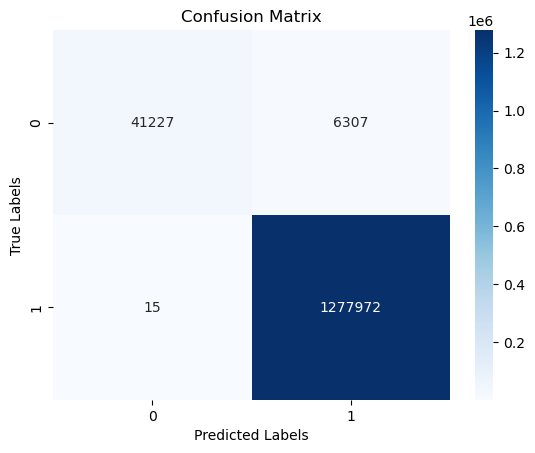

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(val_y, pre_val)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

In [18]:
# Add the predictions to the new dataset
val['PREDICTIONS'] = pre_val

val['TM_STAMP'] = pd.to_datetime(val['TM_STAMP'], unit='s')
val

,Unnamed: 0,ID_PIEZO,TM_STAMP,DIGITS,AMP,SIG2NOISE,REPORTABLE,PREDICTIONS
0,0,1167,2019-07-01 03:00:00,8849.149414,3.5,18.146341,True,1
1,1,1168,2019-07-01 02:00:00,8516.992188,3.5,589.532593,True,1
2,2,1168,2019-07-01 03:00:00,8516.867188,3.5,520.950989,True,1
3,3,1169,2019-07-01 02:00:00,8595.519531,3.5,566.147644,True,1
4,4,1169,2019-07-01 03:00:00,8595.466797,3.5,290.982727,True,1
...,...,...,...,...,...,...,...,...
1439902,1439902,278,2019-08-31 20:00:00,7789.615723,3.5,510.514191,True,1
1439903,1439903,278,2019-08-31 21:00:00,7789.676758,3.5,360.280396,True,1
1439904,1439904,278,2019-08-31 22:00:00,7789.768066,3.5,372.639648,True,1
1439905,1439905,278,2019-08-31 23:00:00,7789.867676,3.5,510.514191,True,1


In [19]:
val['REPORTABLE'] =val['REPORTABLE'].astype('float')

In [20]:
import pandas as pd
from sklearn.metrics import confusion_matrix

# Assuming you already have the new_data dataframe
# Step 2: Create a new column to store the comparison results
val['COMPARE'] = val['REPORTABLE'] == (val['PREDICTIONS'] == 1)

# Get unique ID_PIEZO values for predicted false and actual REPORTABLE false
predicted_false = val.loc[val['PREDICTIONS'] == 0, 'ID_PIEZO'].unique()
actual_reportable_false = val.loc[val['REPORTABLE'] == False, 'ID_PIEZO'].unique()

# Save the unique ID_PIEZO's for predicted false and actual REPORTABLE false in separate text files
with open("PIEZO_Predicted_False.txt", 'w') as f:
    for id_piezo in predicted_false:
        f.write(str(id_piezo) + '\n')

with open("Actual_Piezo_Reportable_False.txt", 'w') as f:
    for id_piezo in actual_reportable_false:
        f.write(str(id_piezo) + '\n')

# Step 4: Create a confusion matrix
y_true = val['REPORTABLE']
y_pred = val['PREDICTIONS'].apply(lambda x: x == 1)  # Convert 1's and 0's to boolean values
cm = confusion_matrix(y_true, y_pred)

# Create a labeled confusion matrix using a Pandas DataFrame
labeled_cm = pd.DataFrame(cm, index=['Actual: False', 'Actual: True'], columns=['Predicted: False', 'Predicted: True'])

print("Confusion Matrix:")

Confusion Matrix:


In [21]:
# importing os module
# Directory
import shutil
import os
directory = "ML_FIGURES"

 

dir ="C:/Temp/ML_FIGURES_4"
if os.path.exists(dir):
    shutil.rmtree(dir)
os.makedirs(dir)

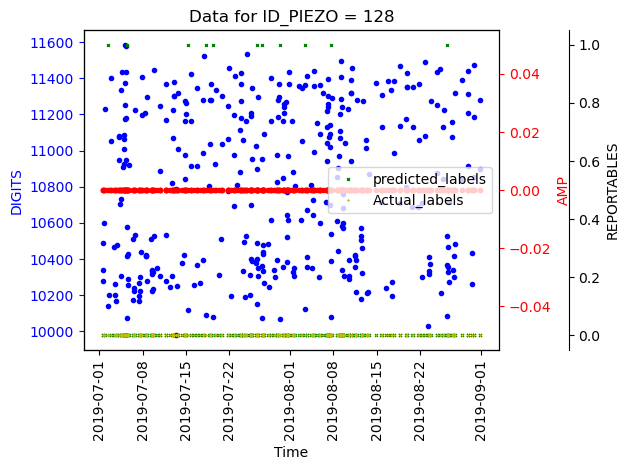

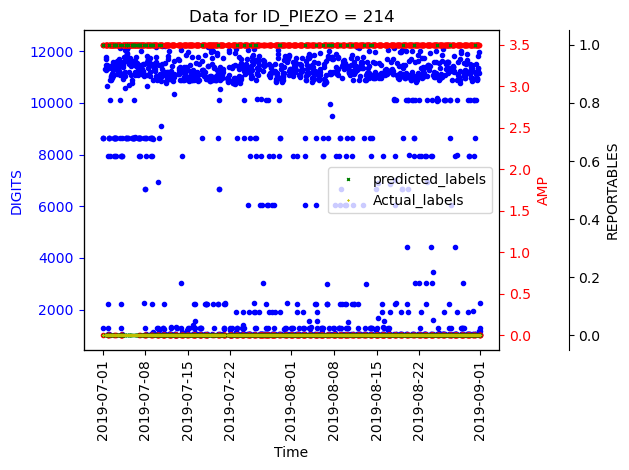

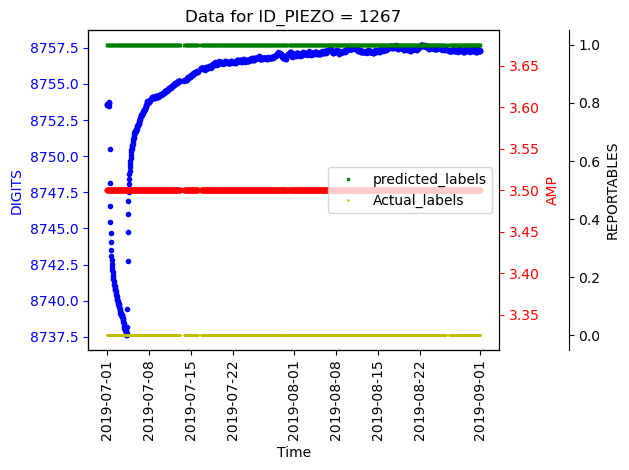

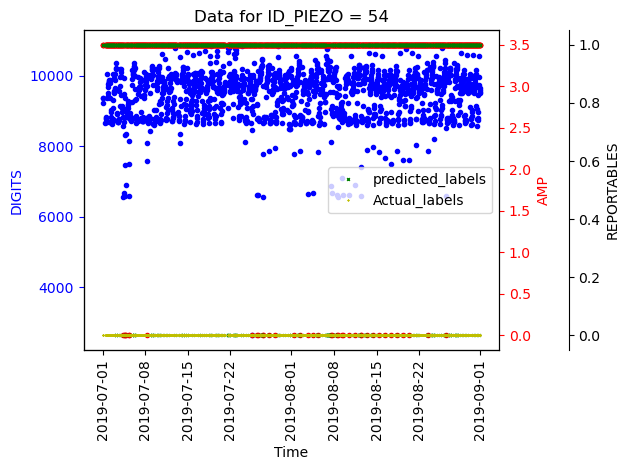

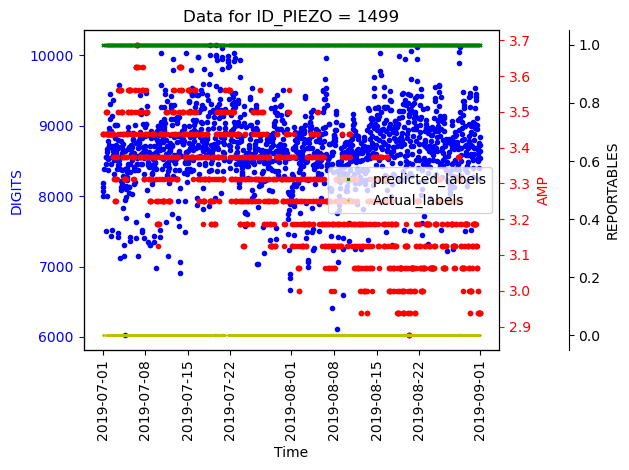

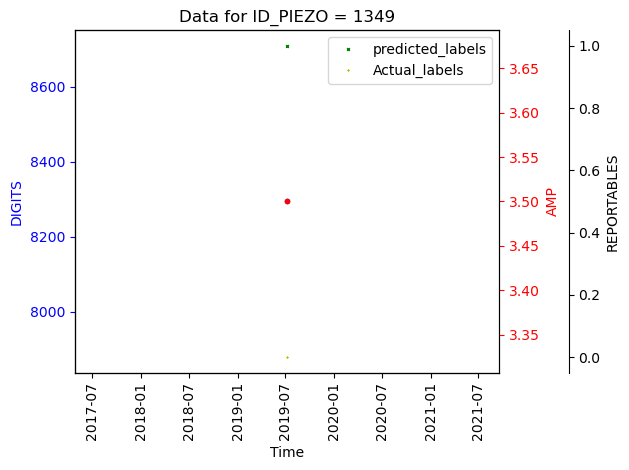

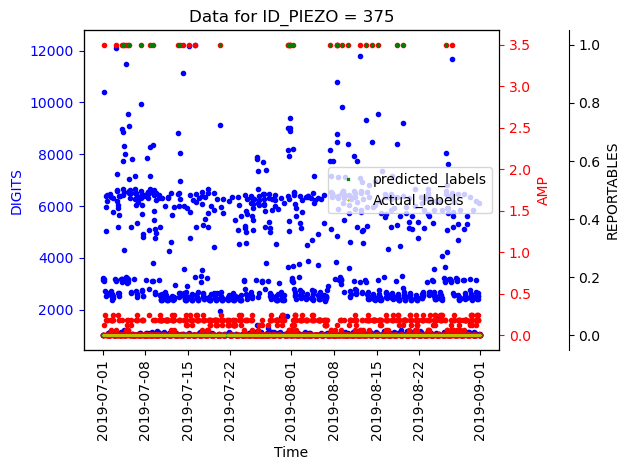

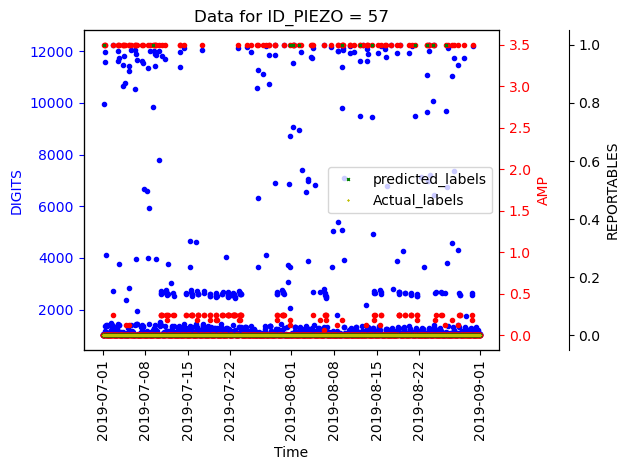

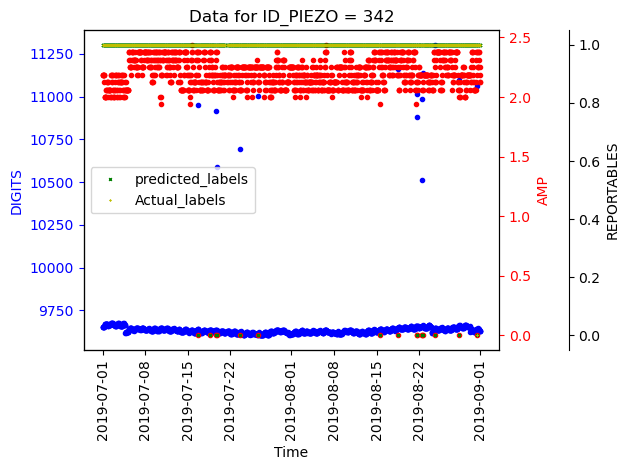

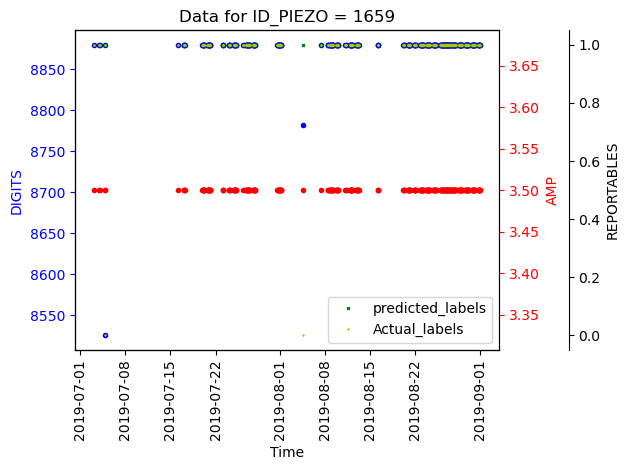

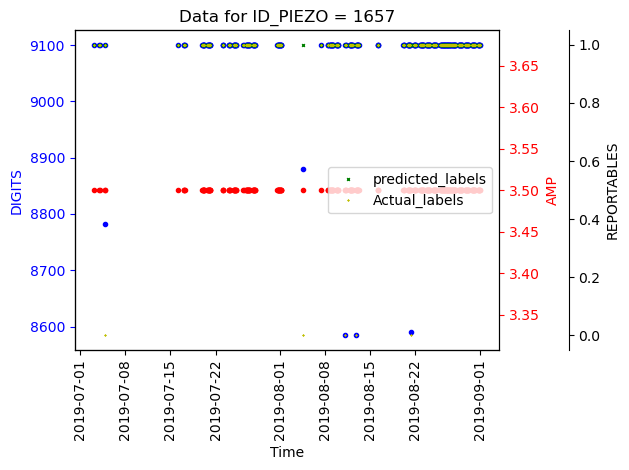

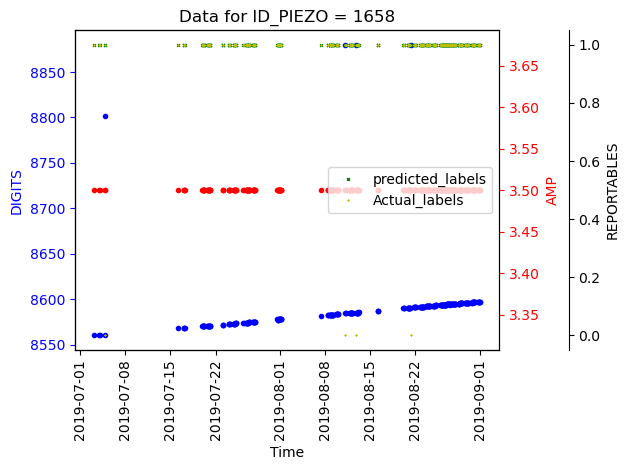

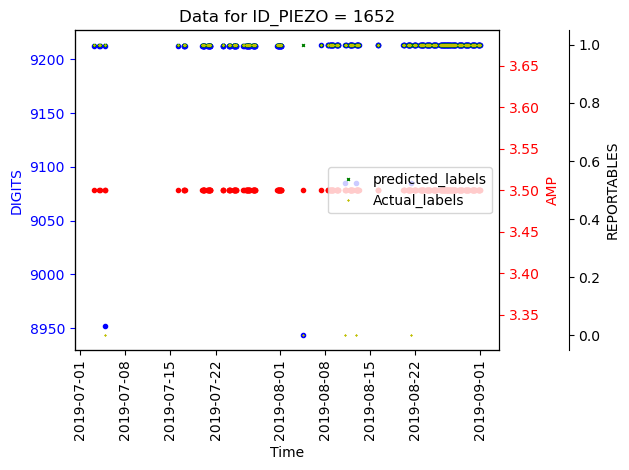

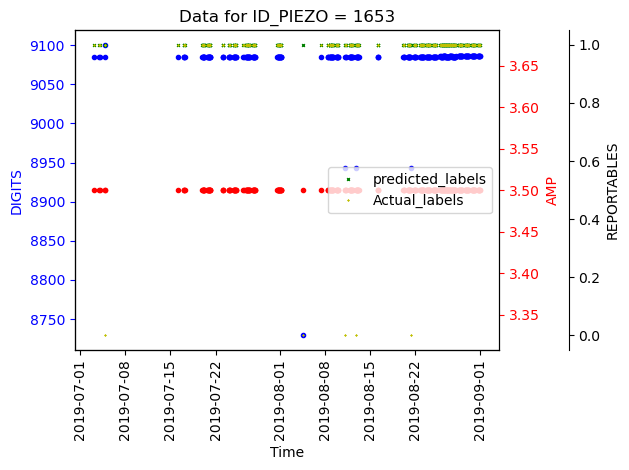

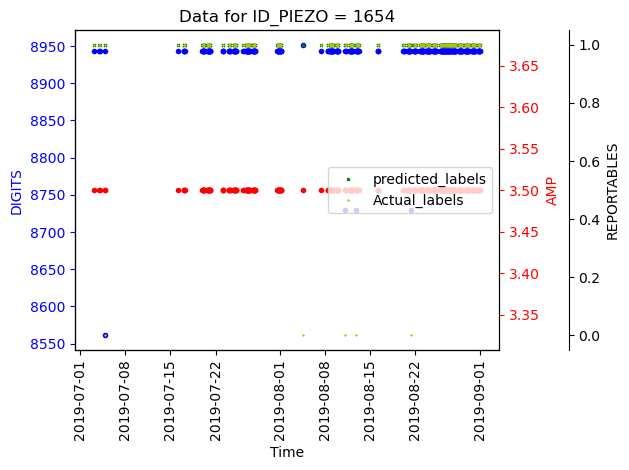

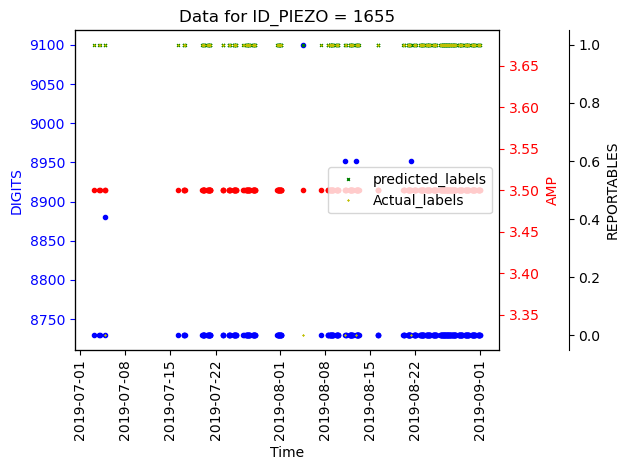

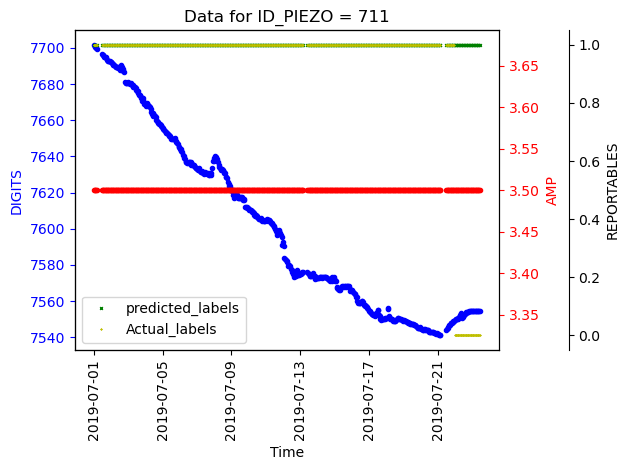

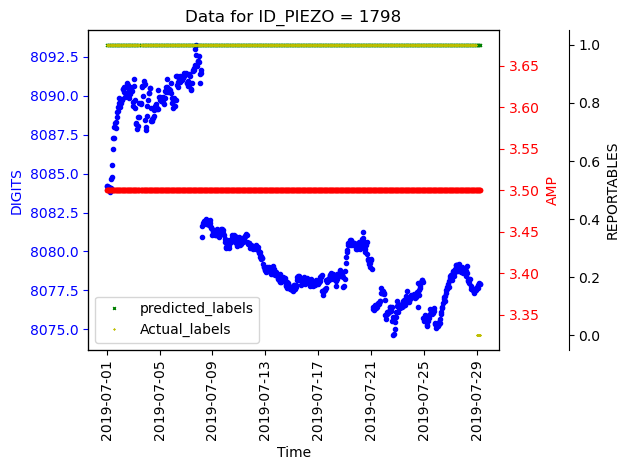

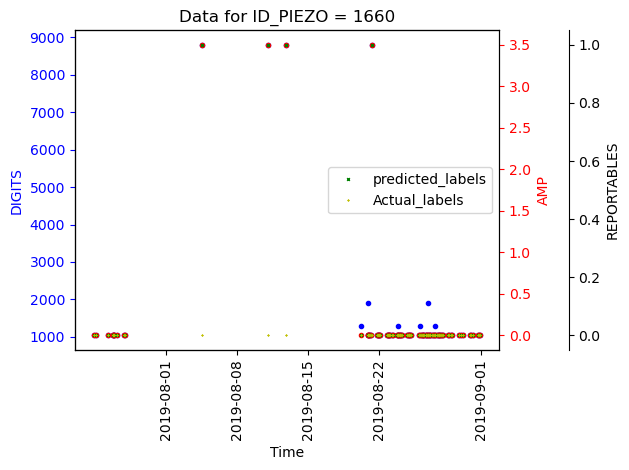

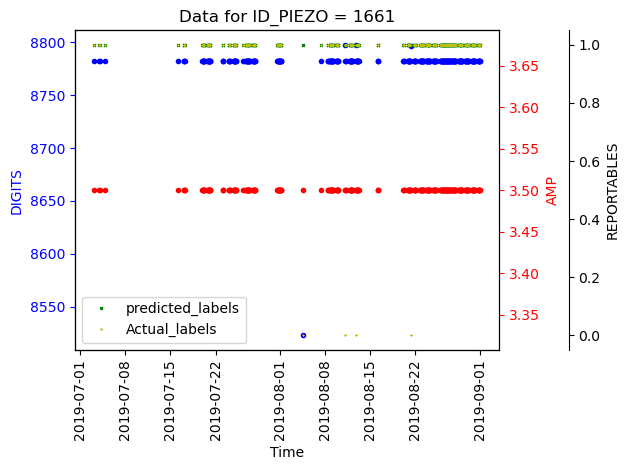

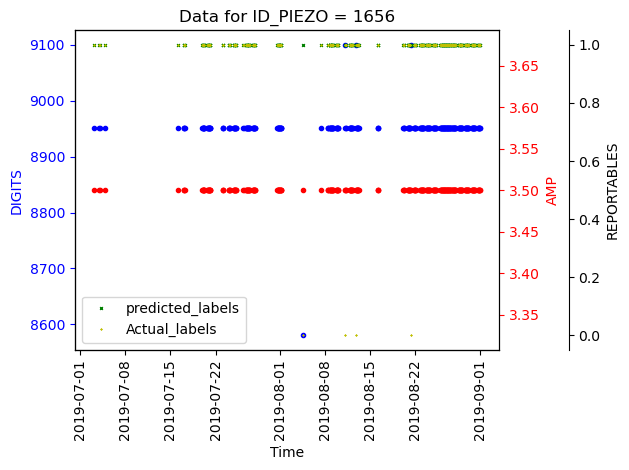

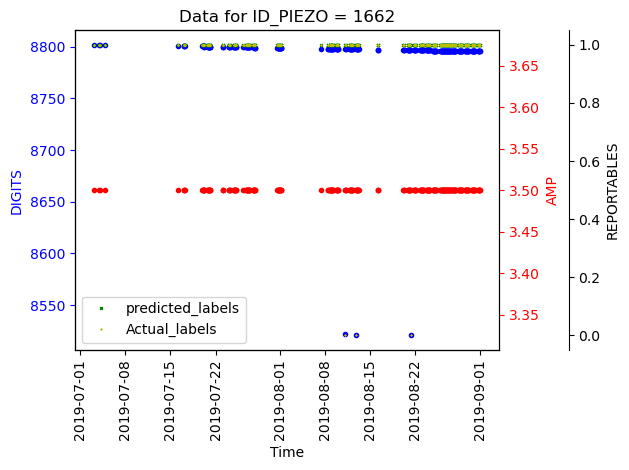

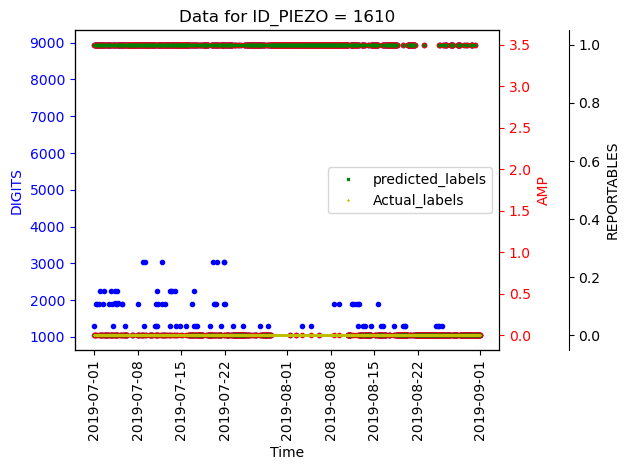

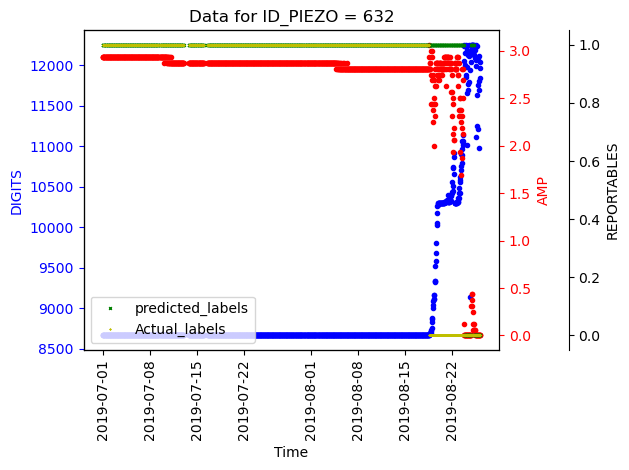

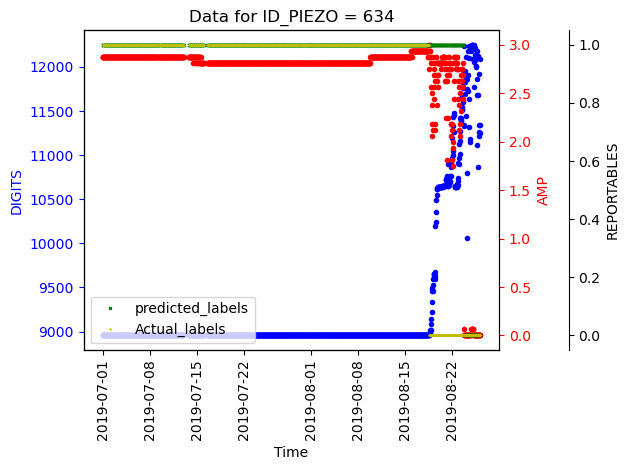

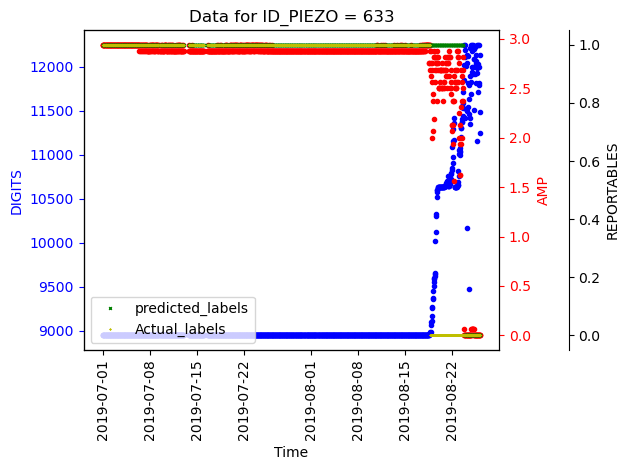

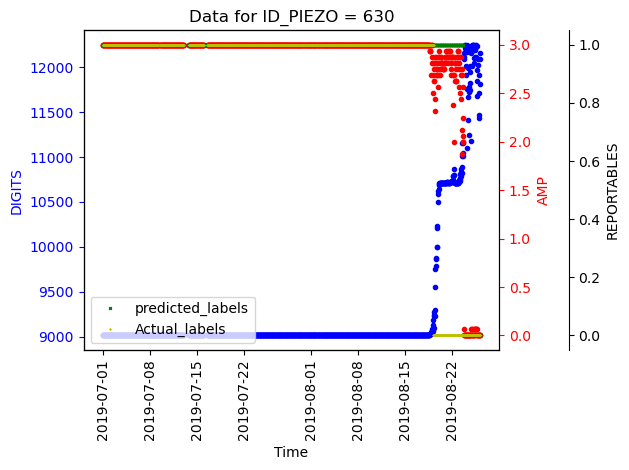

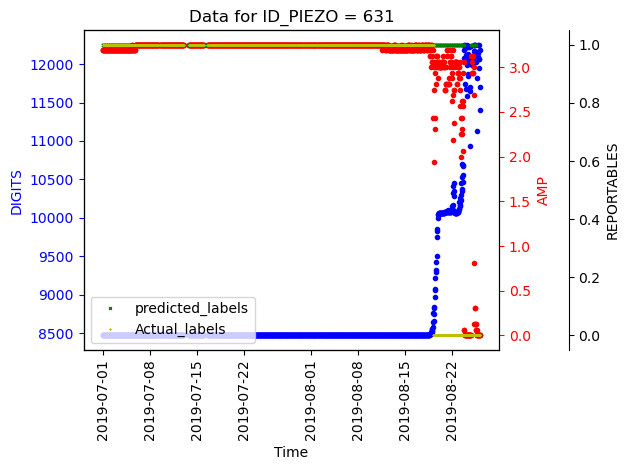

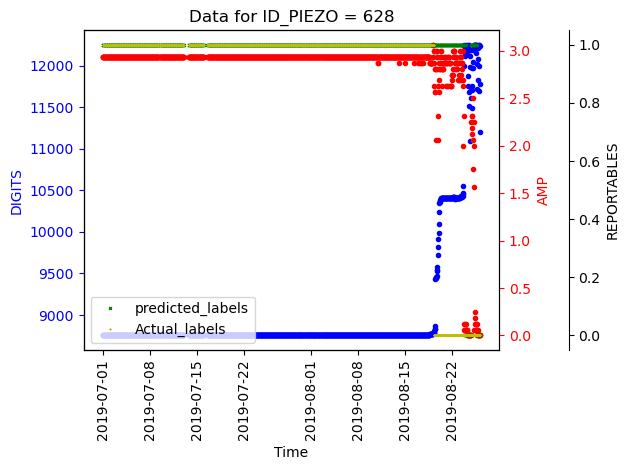

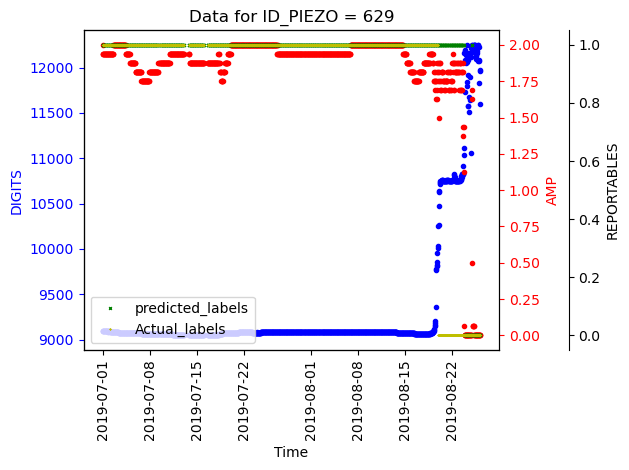

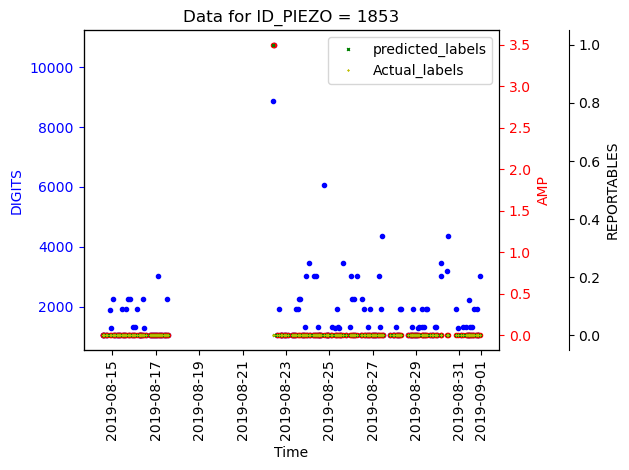

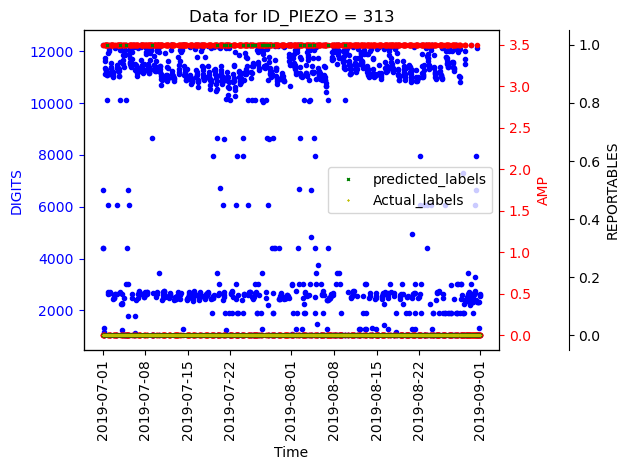

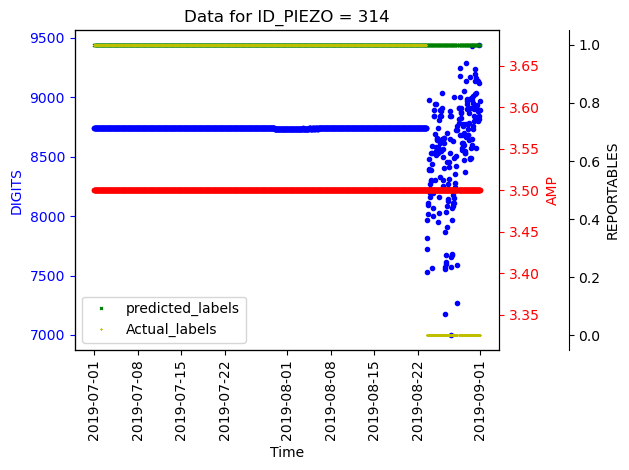

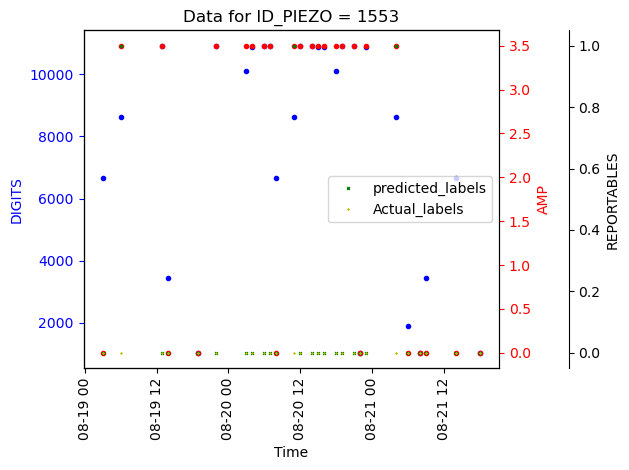

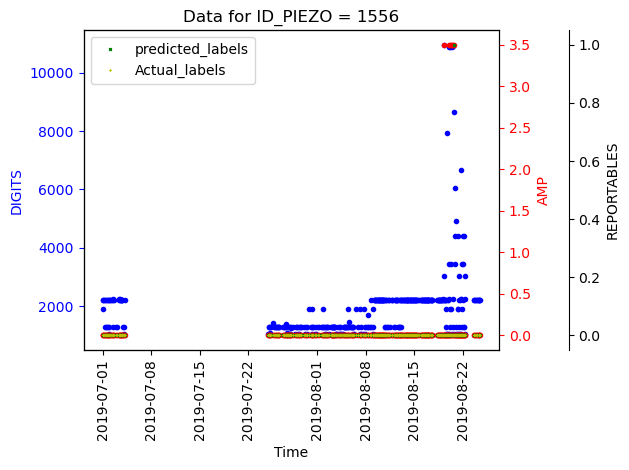

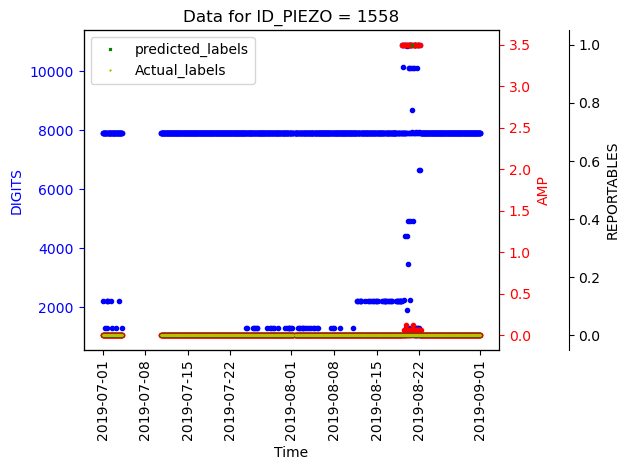

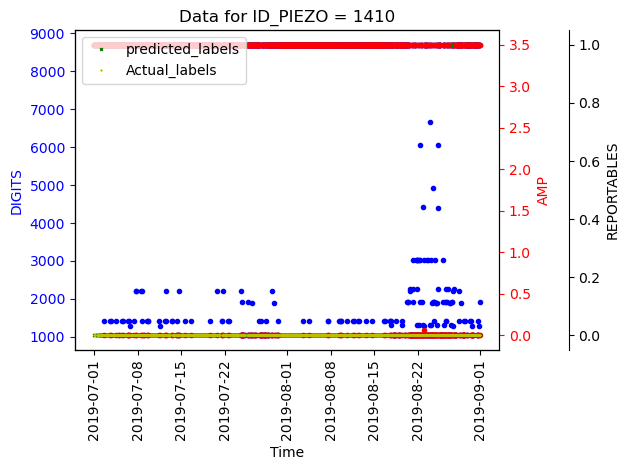

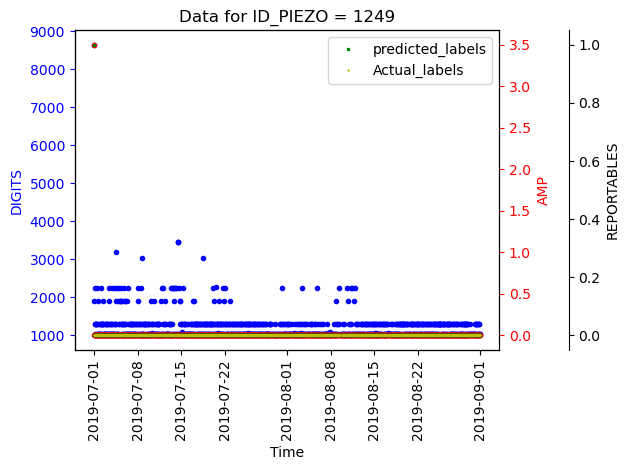

In [22]:
import matplotlib.pyplot as plt

val['REPORTABLE']=val['REPORTABLE']#+0.1

# Filter the dataframe

filtered_df = val[val['COMPARE'] == False]

 

# Get the unique 'ID_PIEZO' values

unique_ids = filtered_df['ID_PIEZO'].unique()



# Plot data for each unique 'ID_PIEZO'

for id in unique_ids:

    # Filter dataframe for the current 'ID_PIEZO'

    df_id = val[val['ID_PIEZO'] == id]
 

    # Create a new figure and two subplots, sharing x-axis

    fig, ax1 = plt.subplots()

 

    # First subplot for 'X' values

    ax1.plot(df_id['TM_STAMP'], df_id['DIGITS'], 'bo', markersize=3)

    ax1.set_xlabel('Time')
    plt.xticks(rotation=90)

    # Make the y-axis label and line color blue to match the line color.

    ax1.set_ylabel('DIGITS', color='b')

    ax1.tick_params('y', colors='b')

 
    # Second subplot for 'Y' values, sharing the same x-axis

    ax2 = ax1.twinx()

    ax2.plot(df_id['TM_STAMP'], df_id['AMP'], 'ro', markersize=3)

    # Make the y-axis label and line color red to match the line color.

    ax2.set_ylabel('AMP', color='r')

    ax2.tick_params('y', colors='r')
    
    # Create a third axis sharing the same x-axis
    ax3 = ax1.twinx()
    #ax4 = ax1.twinx()

    # Offset the third axis
    ax3.spines['right'].set_position(('outward', 50))
    #ax4.spines['right'].set_position(('outward', 90))

    # Plot data on the third axis
    ax3.plot(df_id['TM_STAMP'],df_id['PREDICTIONS'],'gx', markersize=2, label='predicted_labels')
    ax3.plot(df_id['TM_STAMP'],df_id['REPORTABLE'],'yx', markersize=1, label='Actual_labels')
    ax3.set_ylabel('REPORTABLES', color='black')
    ax3.tick_params('y', colors='black')
    
    # Plot data on the fourth axis
    #ax4.plot(df_id['TM_STAMP'],df_id['DIG'], 'mo', markersize=2, label='DIG')
    #ax4.set_ylabel('DIG')
    #ax4.tick_params('y')
    
    
    # Add a legend
    lines = ax3.get_lines()
    ax3.legend(lines, [line.get_label() for line in lines])
    # Add a title to the plot

    plt.title(f"Data for ID_PIEZO = {id}")


    fig.tight_layout()  # This ensures the right y-label is not cut off
    


    plt.show()
    #
    fig.savefig('C:\Temp\ML_FIGURES_4\{0}.png'.format(id), bbox_inches='tight',dpi=300)

In [23]:
import pickle 

In [24]:
# Save the trained model to a file
with open('DIGITS_ML.pkl', 'wb') as f:
    pickle.dump(best_classifier, f)


In [25]:
# Save the StandardScaler object to a file
with open('DIGITS_scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
